# Phase 9: Controlled Combined Degradation Experiment (All 4 Categories)

## Academic Project Context
**Project Title:** *Comparative Analysis of Brain MRI Image Restoration Techniques Under Different Degradation Conditions*

### Objective
In this phase, we model realistic clinical multi-degradation where MRI scans simultaneously experience:
1. **Low-Resolution Downsampling & Interpolation:** Simulating rapid low-field MRI acquisition or thick slice truncation.
2. **Directional Linear Motion Blur:** Simulating involuntary patient motion (tremor, respiration, swallowing) at $\theta = 45^\circ$.
3. **Non-Gaussian Rician Coil Noise:** Simulating intrinsic RF thermal coil noise via physical bivariate Gaussian complex quadrature summation.

### Strict Pipeline Formulation & Order
The degradation pipeline strictly follows the physical clinical sequence:

$$\mathbf{I}_{\text{clean}} \xrightarrow{\text{Low-Res}} \mathbf{I}_{\text{LR}} \xrightarrow{\text{Motion Blur}} \mathbf{I}_{\text{LR+Blur}} \xrightarrow{\text{Rician Noise}} \mathbf{I}_{\text{combined}}$$

- **Training Dataset:** 5,600 clean scans $\times$ 7 severities = **39,200 degraded training scans** saved to `dataset/degraded/combined/`
- **Testing Dataset:** 1,600 clean scans $\times$ 7 severities = **11,200 degraded testing scans** saved to `dataset/degraded_test/combined/`
- **Total Generated Scans:** **50,400 lossless 8-bit Grayscale PNG images** ($512 \times 512$).
- **Original Immutability:** Original clean images (`dataset/archive/`) remain 100% read-only and unmodified.


In [1]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r'C:\Users\gitan\BrainMRI_Project')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.degradation import (
    apply_combined_degradation,
    LOW_RES_SCALE_MAP,
    LOW_RES_DIM_MAP,
    MOTION_BLUR_KERNEL_MAP,
    RICIAN_SIGMA_MAP,
    SEVERITY_LEVELS
)

CATEGORIES = ['glioma', 'meningioma', 'notumor', 'pituitary']
TRAIN_CLEAN_DIR = PROJECT_ROOT / 'dataset' / 'archive' / 'Training'
TEST_CLEAN_DIR  = PROJECT_ROOT / 'dataset' / 'archive' / 'Testing'
TRAIN_DEG_DIR   = PROJECT_ROOT / 'dataset' / 'degraded' / 'combined'
TEST_DEG_DIR    = PROJECT_ROOT / 'dataset' / 'degraded_test' / 'combined'

print('=== Phase 9: Environment & Directory Configuration ===')
print(f'Project Root: {PROJECT_ROOT}')
print(f'Training Degraded Base: {TRAIN_DEG_DIR}')
print(f'Testing Degraded Base:  {TEST_DEG_DIR}')


=== Phase 9: Environment & Directory Configuration ===
Project Root: C:\Users\gitan\BrainMRI_Project
Training Degraded Base: C:\Users\gitan\BrainMRI_Project\dataset\degraded\combined
Testing Degraded Base:  C:\Users\gitan\BrainMRI_Project\dataset\degraded_test\combined


In [2]:
mapping_data = []
for sev in SEVERITY_LEVELS:
    scale = LOW_RES_SCALE_MAP[sev]
    dim = LOW_RES_DIM_MAP[sev]
    k_len = MOTION_BLUR_KERNEL_MAP[sev]
    sigma = RICIAN_SIGMA_MAP[sev]
    mapping_data.append({
        'Severity (%)': f'{sev}%',
        'LR Scale Factor': f'{scale:.4f}',
        'Downsampled Resolution': f'{dim}x{dim}',
        'Motion Kernel (L)': f'{k_len} px (45°)',
        'Rician Noise Sigma (σ)': f'{sigma:.2f}',
        'Clinical Distortion Model': f'LR({dim}x{dim}) + Blur({k_len}px) + Rician(σ={sigma:.2f})'
    })

df_mapping = pd.DataFrame(mapping_data)
print('=== Phase 9: Combined Multi-Degradation Severity Parameter Mapping ===')
print(df_mapping.to_string(index=False))


=== Phase 9: Combined Multi-Degradation Severity Parameter Mapping ===
Severity (%) LR Scale Factor Downsampled Resolution Motion Kernel (L) Rician Noise Sigma (σ)                 Clinical Distortion Model
         10%          0.9000                461x461        5 px (45°)                   0.10  LR(461x461) + Blur(5px) + Rician(σ=0.10)
         20%          0.8000                410x410        9 px (45°)                   0.20  LR(410x410) + Blur(9px) + Rician(σ=0.20)
         30%          0.7000                358x358       13 px (45°)                   0.30 LR(358x358) + Blur(13px) + Rician(σ=0.30)
         40%          0.6000                307x307       17 px (45°)                   0.40 LR(307x307) + Blur(17px) + Rician(σ=0.40)
         50%          0.5000                256x256       21 px (45°)                   0.50 LR(256x256) + Blur(21px) + Rician(σ=0.50)
         60%          0.4000                205x205       25 px (45°)                   0.60 LR(205x205) + Blur(25px) +

In [3]:
train_audit = []
all_train_matched = True
for cat in CATEGORIES:
    clean_count = len(list((TRAIN_CLEAN_DIR / cat).glob('*.*')))
    for sev in SEVERITY_LEVELS:
        sev_dir = TRAIN_DEG_DIR / cat / str(sev)
        deg_count = len(list(sev_dir.glob('*.png')))
        matched = (deg_count == clean_count)
        if not matched:
            all_train_matched = False
        train_audit.append({
            'Dataset': 'Training',
            'Category': cat,
            'Severity': f'{sev}%',
            'Clean Count': clean_count,
            'Degraded Count': deg_count,
            'Match': matched
        })

df_train_audit = pd.DataFrame(train_audit)
print('=== Training Combined Degraded Dataset Audit (39,200 Scans) ===')
print(df_train_audit.to_string(index=False))
print(f'\nTotal Training Combined Degraded Images: {df_train_audit["Degraded Count"].sum()} / 39,200 expected')
print(f'All Training Counts Match: {all_train_matched}')


=== Training Combined Degraded Dataset Audit (39,200 Scans) ===
 Dataset   Category Severity  Clean Count  Degraded Count  Match
Training     glioma      10%         1400            1400   True
Training     glioma      20%         1400            1400   True
Training     glioma      30%         1400            1400   True
Training     glioma      40%         1400            1400   True
Training     glioma      50%         1400            1400   True
Training     glioma      60%         1400            1400   True
Training     glioma      70%         1400            1400   True
Training meningioma      10%         1400            1400   True
Training meningioma      20%         1400            1400   True
Training meningioma      30%         1400            1400   True
Training meningioma      40%         1400            1400   True
Training meningioma      50%         1400            1400   True
Training meningioma      60%         1400            1400   True
Training meningioma      7

In [4]:
test_audit = []
all_test_matched = True
for cat in CATEGORIES:
    clean_count = len(list((TEST_CLEAN_DIR / cat).glob('*.*')))
    for sev in SEVERITY_LEVELS:
        sev_dir = TEST_DEG_DIR / cat / str(sev)
        deg_count = len(list(sev_dir.glob('*.png')))
        matched = (deg_count == clean_count)
        if not matched:
            all_test_matched = False
        test_audit.append({
            'Dataset': 'Testing',
            'Category': cat,
            'Severity': f'{sev}%',
            'Clean Count': clean_count,
            'Degraded Count': deg_count,
            'Match': matched
        })

df_test_audit = pd.DataFrame(test_audit)
print('=== Testing Combined Degraded Dataset Audit (11,200 Scans) ===')
print(df_test_audit.to_string(index=False))
print(f'\nTotal Testing Combined Degraded Images: {df_test_audit["Degraded Count"].sum()} / 11,200 expected')
print(f'All Testing Counts Match: {all_test_matched}')


=== Testing Combined Degraded Dataset Audit (11,200 Scans) ===
Dataset   Category Severity  Clean Count  Degraded Count  Match
Testing     glioma      10%          400             400   True
Testing     glioma      20%          400             400   True
Testing     glioma      30%          400             400   True
Testing     glioma      40%          400             400   True
Testing     glioma      50%          400             400   True
Testing     glioma      60%          400             400   True
Testing     glioma      70%          400             400   True
Testing meningioma      10%          400             400   True
Testing meningioma      20%          400             400   True
Testing meningioma      30%          400             400   True
Testing meningioma      40%          400             400   True
Testing meningioma      50%          400             400   True
Testing meningioma      60%          400             400   True
Testing meningioma      70%          400 

In [5]:
sample_records = []
for cat in CATEGORIES:
    first_clean = sorted(list((TRAIN_CLEAN_DIR / cat).glob('*.*')))[0]
    stem = first_clean.stem
    for sev in [10, 40, 70]:
        p = TRAIN_DEG_DIR / cat / str(sev) / f'{stem}_combined_{sev}.png'
        with Image.open(p) as img:
            arr = np.array(img)
            sample_records.append({
                'Category': cat,
                'Severity': f'{sev}%',
                'Resolution': f'{img.size[0]}x{img.size[1]}',
                'Mode': img.mode,
                'Min Pixel': int(arr.min()),
                'Max Pixel': int(arr.max()),
                'Dtype': str(arr.dtype)
            })

print('=== Sample Format, Mode & Dynamic Range Audit ===')
print(pd.DataFrame(sample_records).to_string(index=False))

# Verify original datasets remain untouched
train_orig = {cat: len(list((TRAIN_CLEAN_DIR / cat).glob('*.*'))) for cat in CATEGORIES}
test_orig  = {cat: len(list((TEST_CLEAN_DIR / cat).glob('*.*'))) for cat in CATEGORIES}
print(f'\nOriginal Training Image Counts (Untouched): {train_orig}')
print(f'Original Testing Image Counts (Untouched):  {test_orig}')


=== Sample Format, Mode & Dynamic Range Audit ===
  Category Severity Resolution Mode  Min Pixel  Max Pixel Dtype
    glioma      10%    512x512    L          0        255 uint8
    glioma      40%    512x512    L          0        255 uint8
    glioma      70%    512x512    L          0        255 uint8
meningioma      10%    512x512    L          0        255 uint8
meningioma      40%    512x512    L          0        255 uint8
meningioma      70%    512x512    L          0        255 uint8
   notumor      10%    512x512    L          0        255 uint8
   notumor      40%    512x512    L          0        255 uint8
   notumor      70%    512x512    L          0        255 uint8
 pituitary      10%    512x512    L          0        255 uint8
 pituitary      40%    512x512    L          0        255 uint8
 pituitary      70%    512x512    L          0        255 uint8

Original Training Image Counts (Untouched): {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}


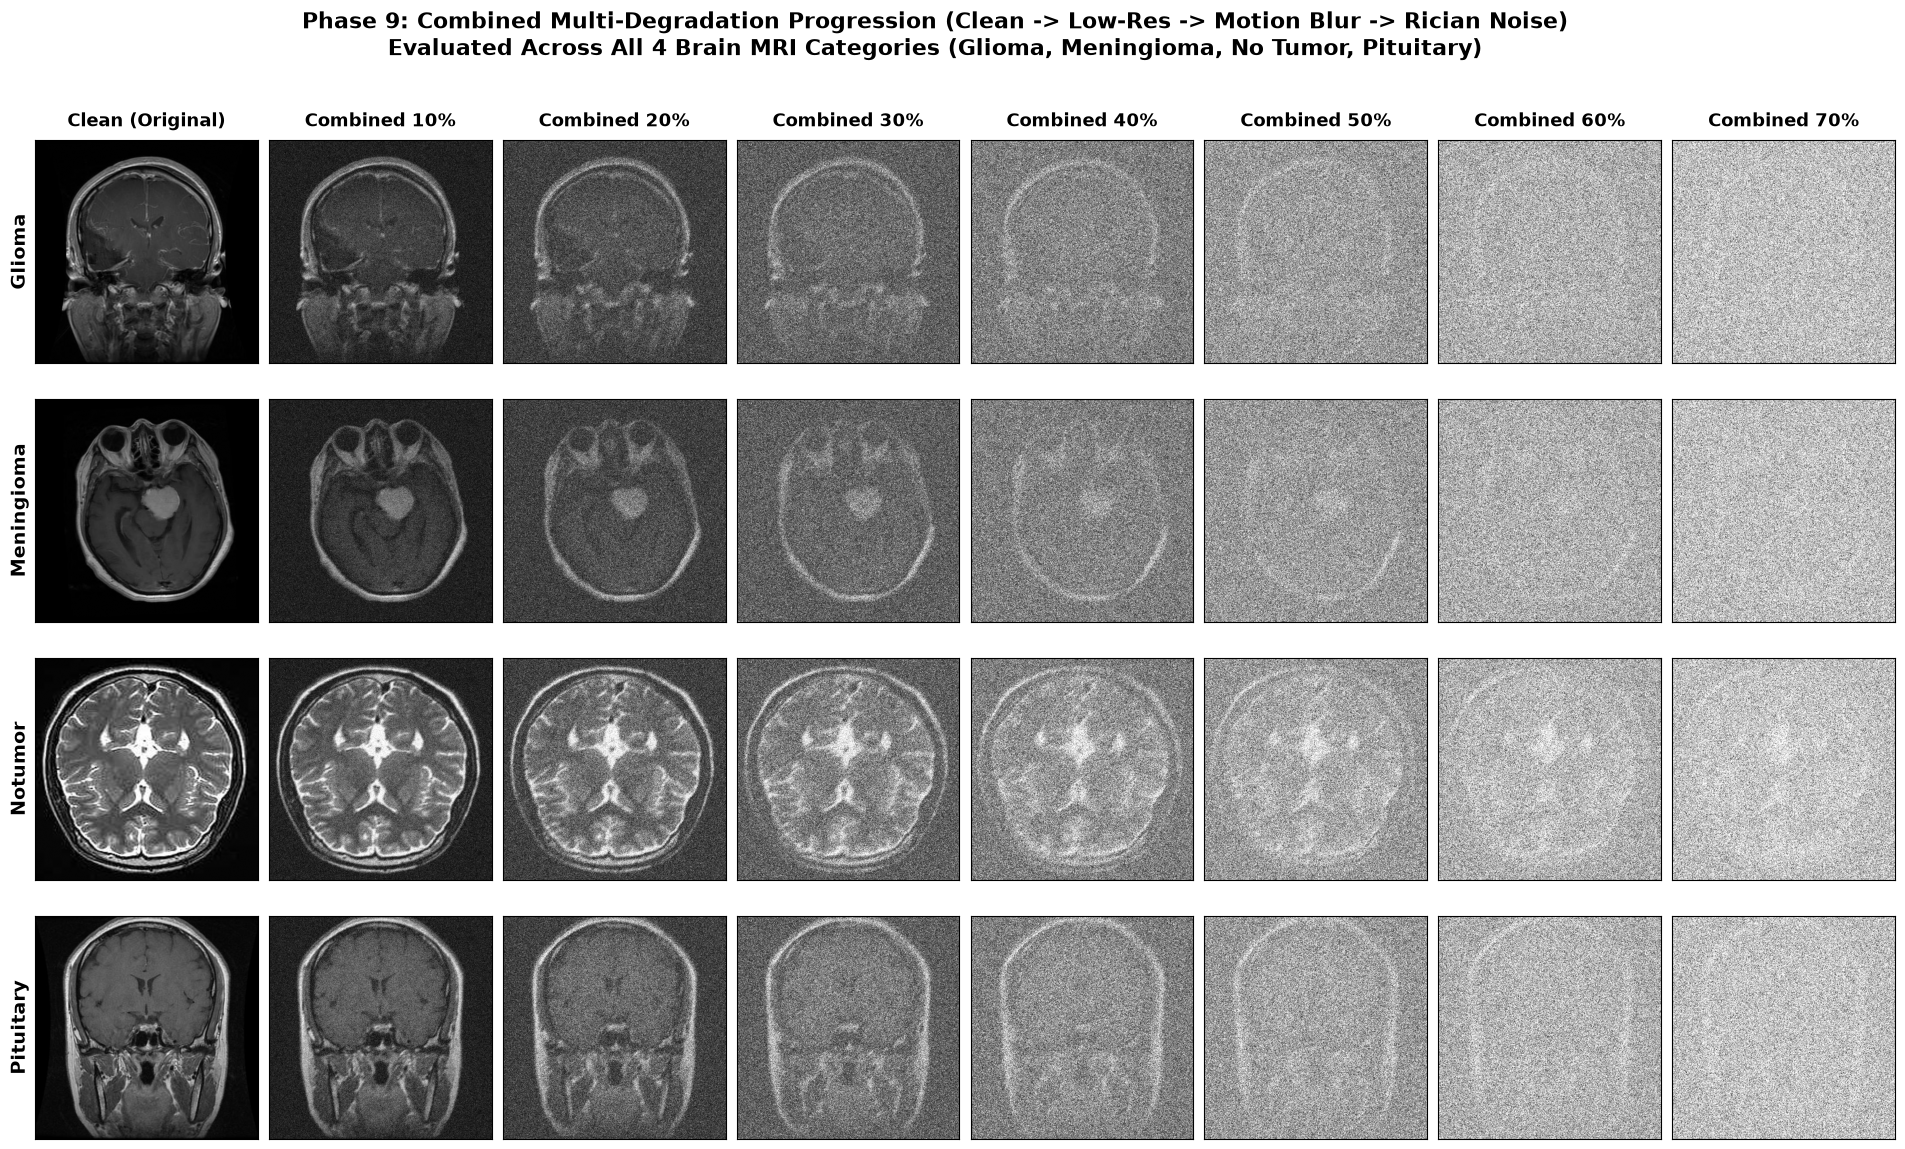

In [6]:
fig, axes = plt.subplots(nrows=4, ncols=8, figsize=(24, 13))
plt.subplots_adjust(wspace=0.05, hspace=0.15)

col_titles = ['Clean (Original)'] + [f'Combined {s}%' for s in SEVERITY_LEVELS]

for row_idx, cat in enumerate(CATEGORIES):
    clean_files = sorted(list((TRAIN_CLEAN_DIR / cat).glob('*.*')))
    rep_img_path = clean_files[0]
    stem = rep_img_path.stem

    # Clean original
    with Image.open(rep_img_path) as img:
        clean_arr = np.array(img.convert('L').resize((512, 512)))

    axes[row_idx, 0].imshow(clean_arr, cmap='gray', vmin=0, vmax=255)
    axes[row_idx, 0].set_ylabel(cat.capitalize(), fontsize=14, fontweight='bold')
    axes[row_idx, 0].set_xticks([])
    axes[row_idx, 0].set_yticks([])
    if row_idx == 0:
        axes[row_idx, 0].set_title(col_titles[0], fontsize=13, fontweight='bold', pad=10)

    # Severities
    for col_idx, sev in enumerate(SEVERITY_LEVELS, start=1):
        deg_path = TRAIN_DEG_DIR / cat / str(sev) / f'{stem}_combined_{sev}.png'
        with Image.open(deg_path) as img:
            deg_arr = np.array(img)

        axes[row_idx, col_idx].imshow(deg_arr, cmap='gray', vmin=0, vmax=255)
        axes[row_idx, col_idx].set_xticks([])
        axes[row_idx, col_idx].set_yticks([])
        if row_idx == 0:
            axes[row_idx, col_idx].set_title(col_titles[col_idx], fontsize=13, fontweight='bold', pad=10)

fig.suptitle(
    'Phase 9: Combined Multi-Degradation Progression (Clean -> Low-Res -> Motion Blur -> Rician Noise)\n'
    'Evaluated Across All 4 Brain MRI Categories (Glioma, Meningioma, No Tumor, Pituitary)',
    fontsize=16, fontweight='bold', y=0.98
)
plt.show()
